# AMH vs AN Model Selection
Loads the batch results produced by `model_selection.py` (`evaluate_dataframe`)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 300
from matplotlib import rc; rc('text', usetex=True)
plt.rcParams.update({'font.size': 22})
plt.rcParams["font.family"] = "serif"

AMH_COLOR = '#1d9e75'
AN_COLOR  = '#d85a30'

In [2]:
# !python3 model_selection.py

In [3]:
SEL_DIR = "model_selecction_results"          # from model_selection.py
AMH_SEL_PATH = os.path.join(SEL_DIR, "amh.pkl")
AN_SEL_PATH  = os.path.join(SEL_DIR, "an.pkl")

# original per-network dataframes (contain ground-truth kt/b/kp and zeta/kappa)
AMH_TRUE_PATH = "amh_float32_32/results_df_20260705_152636.pkl"
AN_TRUE_PATH  = "an_psi_results_old/results_df_20260705_153631.pkl"

amh_sel = pd.read_pickle(AMH_SEL_PATH)
an_sel  = pd.read_pickle(AN_SEL_PATH)

amh_true = pd.read_pickle(AMH_TRUE_PATH)   # columns: kt, kt_pred, kp, kp_pred, b, b_pred, vx, vy, phi
an_true  = pd.read_pickle(AN_TRUE_PATH)    # columns: zeta, zeta_pred, kappa, kappa_pred, vx, vy, theta

print(f'AMH selection rows: {len(amh_sel)}   AN selection rows: {len(an_sel)}')
print(f'AMH truth rows    : {len(amh_true)}   AN truth rows    : {len(an_true)}')

AMH selection rows: 100   AN selection rows: 100
AMH truth rows    : 100   AN truth rows    : 100


In [4]:
amh_sel = amh_sel.reset_index(drop=True)
an_sel  = an_sel.reset_index(drop=True)
amh_true = amh_true.reset_index(drop=True)
an_true  = an_true.reset_index(drop=True)

amh_sel['k_tilde_true'] = amh_true['kt']
amh_sel['b_true']       = amh_true['b']
amh_sel['kp_true']      = amh_true['kp']

an_sel['zeta_true']  = an_true['zeta']
an_sel['kappa_true'] = an_true['kappa']

results = pd.concat([amh_sel, an_sel], ignore_index=True)
display(results.head())
display(results.tail())

,true_model,model_winner,correct,model_conf,d_AMH,d_AN,c_AMH,c_AN,score_ratio,k_tilde_pred,b_pred,kp_pred,kappa_pred,zeta_pred,k_tilde_true,b_true,kp_true,zeta_true,kappa_true
0,AMH,AMH,True,0.852393,0.661041,10.065551,0.852393,0.147607,0.065674,-0.664232,1.040487,1.162851,0.478393,-0.180479,0.788006,0.981994,1.180286,NaN,NaN
1,AMH,AMH,True,0.875031,0.092032,6.749843,0.875031,0.124969,0.013635,-0.320547,1.201287,1.053390,0.346546,-0.258410,0.402217,1.123423,0.994668,NaN,NaN
2,AMH,AMH,True,0.876785,0.045397,4.774744,0.876785,0.123215,0.009508,-0.677627,0.295004,1.137487,0.652120,-0.048870,0.504017,0.254363,1.081543,NaN,NaN
3,AMH,AMH,True,0.876532,0.041315,4.089372,0.876532,0.123468,0.010103,-0.903719,0.439020,1.145886,0.565057,-0.057716,1.067574,0.431183,1.175412,NaN,NaN
4,AMH,AMH,True,0.863479,0.192623,4.762047,0.863479,0.136521,0.040450,-0.684449,0.963227,0.856970,0.385610,-0.272180,0.644899,0.941720,0.802941,NaN,NaN


,true_model,model_winner,correct,model_conf,d_AMH,d_AN,c_AMH,c_AN,score_ratio,k_tilde_pred,b_pred,kp_pred,kappa_pred,zeta_pred,k_tilde_true,b_true,kp_true,zeta_true,kappa_true
195,AN,AN,True,0.860408,0.841836,0.039972,0.139592,0.860408,21.060389,-1.425685,1.600321,0.813264,1.878739,-1.160236,NaN,NaN,NaN,1.153461,1.919372
196,AN,AN,True,0.837184,1.578917,0.157386,0.162816,0.837184,10.032124,-1.339228,1.365798,0.827412,0.844997,-0.721142,NaN,NaN,NaN,0.775786,0.907014
197,AN,AN,True,0.833371,2.848442,0.307979,0.166629,0.833371,9.248817,-1.173179,1.084654,0.931419,0.958945,-0.596291,NaN,NaN,NaN,0.568110,0.931799
198,AN,AN,True,0.876930,1.387886,0.012720,0.123070,0.876930,109.109142,-1.385322,1.540862,0.826597,1.458901,-1.101436,NaN,NaN,NaN,1.056394,1.244637
199,AN,AN,True,0.870837,24.621521,0.577184,0.129163,0.870837,42.658010,-14.064668,0.212796,1.474853,1.504999,-0.341450,NaN,NaN,NaN,0.345385,1.409494


In [5]:
results['log_ratio'] = np.log10(results['d_AN'] / results['d_AMH'])

##  Classification accuracy

In [6]:
summary_rows = []
for true_label in ['AMH', 'AN']:
    sub = results[results['true_model'] == true_label]
    acc = sub['correct'].mean() * 100
    summary_rows.append(dict(
        true_model=true_label,
        n=len(sub),
        accuracy_pct=acc,
        mean_d_AMH=sub['d_AMH'].mean(),
        mean_d_AN=sub['d_AN'].mean(),
        mean_conf_correct=sub.loc[sub['correct'], 'model_conf'].mean(),
    ))

summary_df = pd.DataFrame(summary_rows)
overall_acc = results['correct'].mean() * 100
print(summary_df.to_string(index=False, float_format='%.3f'))
print(f'\nOverall accuracy: {overall_acc:.1f}%  ({results["correct"].sum()}/{len(results)})')

true_model   n  accuracy_pct  mean_d_AMH  mean_d_AN  mean_conf_correct
       AMH 100       100.000       0.366      7.611              0.863
        AN 100        99.000       9.410      0.425              0.844

Overall accuracy: 99.5%  (199/200)


## Parameter recovery (predicted vs. true)


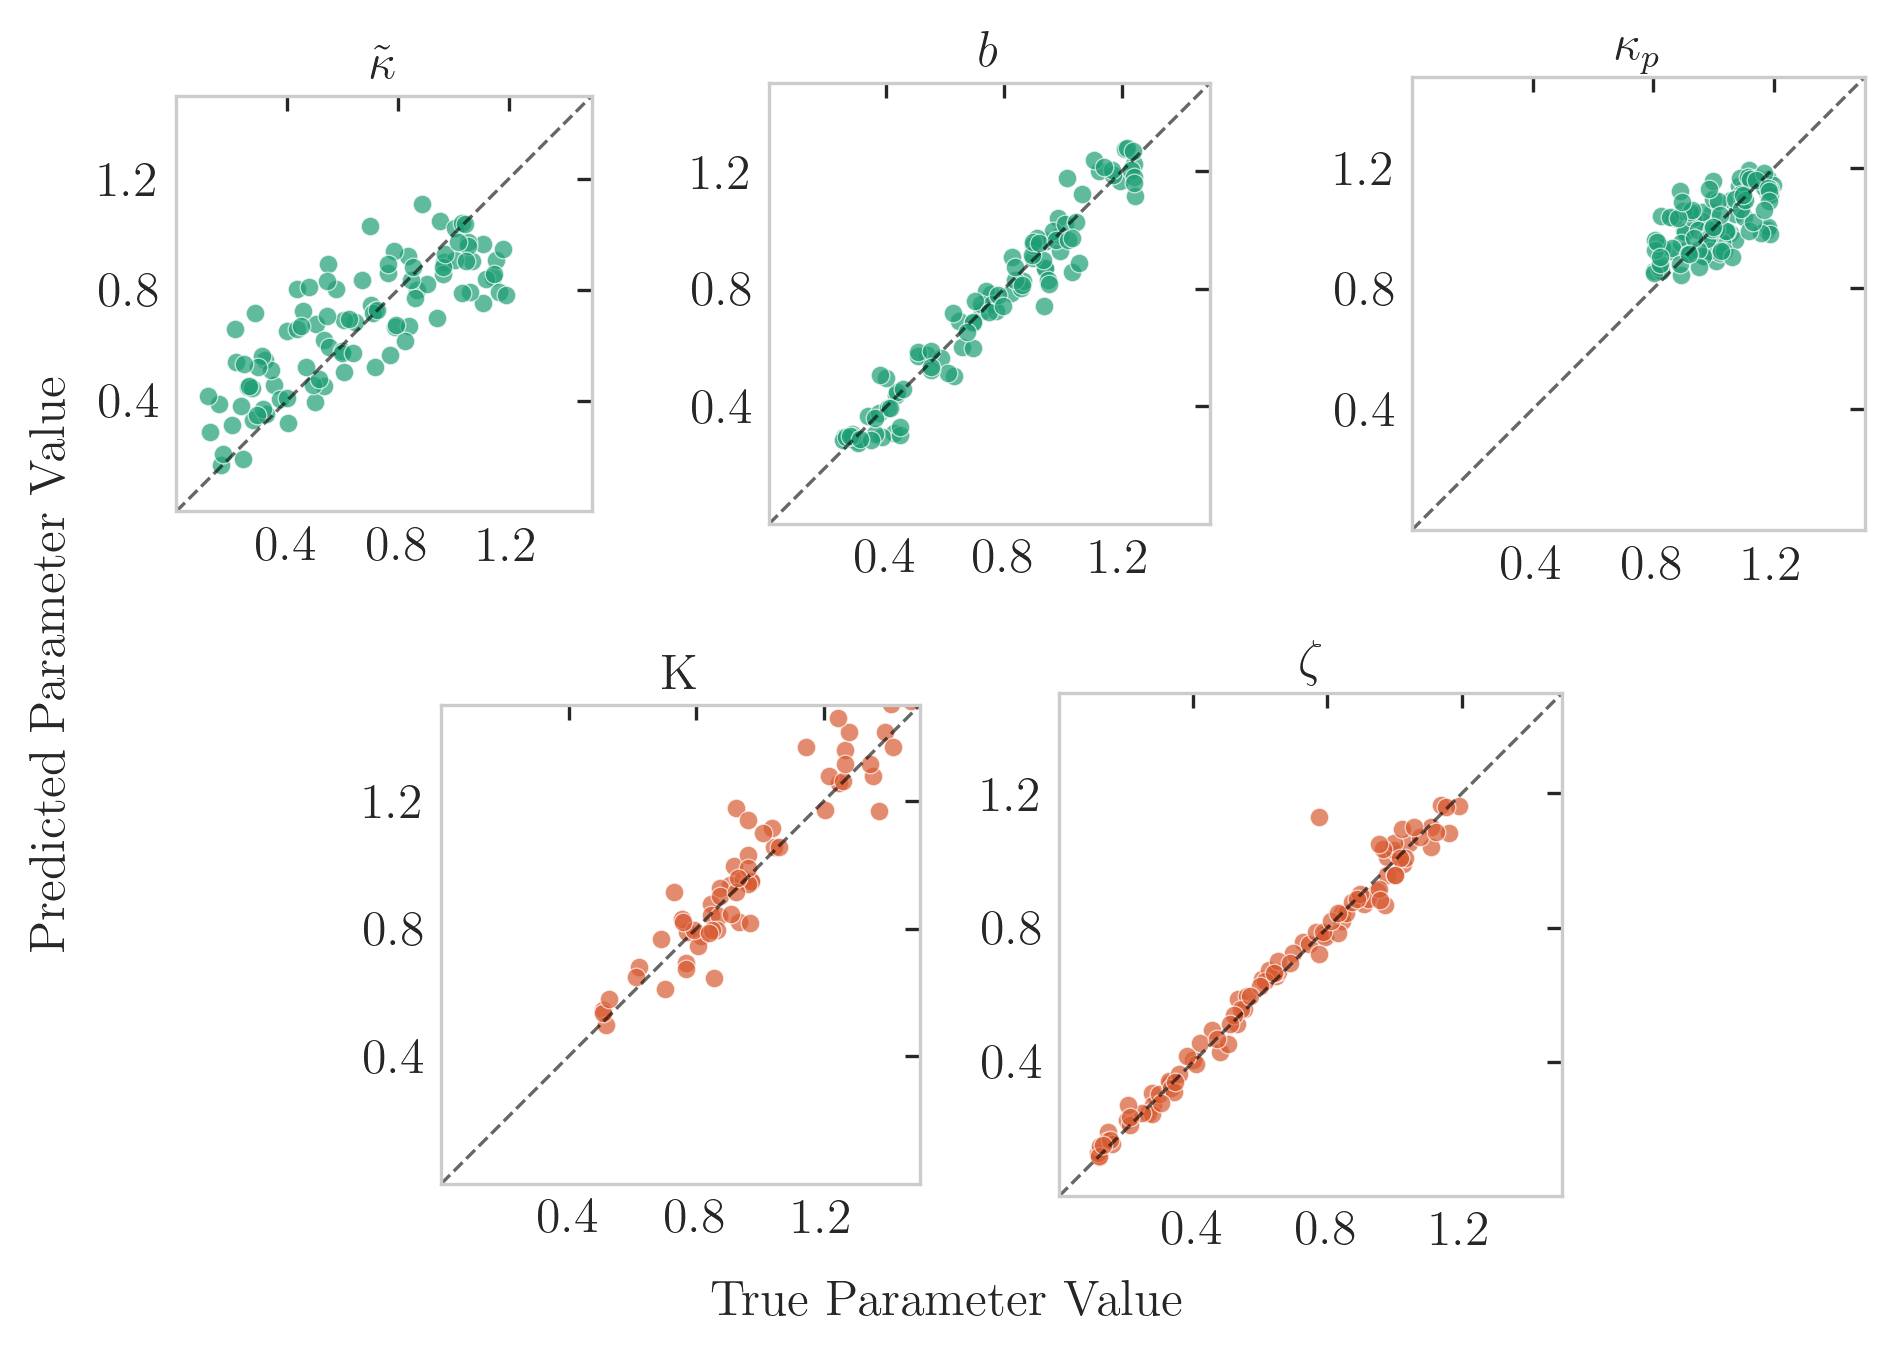

In [31]:
from matplotlib.gridspec import GridSpec

amh_only = results[results['true_model'] == 'AMH']
an_only  = results[results['true_model'] == 'AN']

param_specs = [
    (amh_only, 'k_tilde_true', 'k_tilde_pred', r'$\tilde\kappa$', AMH_COLOR),
    (amh_only, 'b_true',       'b_pred',       r'$b$',            AMH_COLOR),
    (amh_only, 'kp_true',      'kp_pred',      r'$\kappa_p$',     AMH_COLOR),
    (an_only,  'kappa_true',   'kappa_pred',   r'K',       AN_COLOR),
    (an_only,  'zeta_true',    'zeta_pred',    r'$\zeta$',        AN_COLOR),
]


from matplotlib.gridspec import GridSpec

# --- 1. Apply APS / RevTeX Paper Formatting ---
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "Times New Roman"],
    "mathtext.fontset": "cm", # Matches LaTeX math font
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "in", # Standard physics paper tick direction
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.0,
})

# Assume amh_only, an_only, param_specs, AMH_COLOR, AN_COLOR are already defined

# --- 2. Setup Figure ---
fig = plt.figure(figsize=(6.2, 4.5), layout="constrained")

# We can squeeze the horizontal and vertical spacing between grid cells natively here
gs = GridSpec(2, 6, figure=fig, wspace=0.05, hspace=0.05) 
axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 1:3]), 
    fig.add_subplot(gs[1, 3:5]), 
]

lims = [0.0, 1.5]
ticks = [0.4, 0.8, 1.2]

for ax, (sub, true_col, pred_col, sym, color) in zip(axes, param_specs):
    t = sub[true_col].abs()
    p = sub[pred_col].abs()
    
    ax.grid(False)
    ax.scatter(t, p, color=color, alpha=0.7, edgecolors='white', linewidth=0.3, s=20)
    
    # Draw y=x line
    ax.plot(lims, lims, '--', color='black', alpha=0.6, linewidth=0.8)
    
    # Enforce strict axis limits and clean up tick labels
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    
    # Title
    ax.set_title(sym, pad=4)
    
    # Keep plots perfectly square
    ax.set_aspect('equal', adjustable='box')

# --- 3. Global Labels ---
fig.supxlabel('True Parameter Value', fontsize=12)
fig.supylabel('Predicted Parameter Value', fontsize=12)

# # Save as high-resolution PNG (600 DPI is standard for APS print quality)
plt.savefig('model_selecction_results/parameter_recovery.png', dpi=300)
# # Save as PDF for LaTeX (vector format won't pixelate when zoomed)
# plt.savefig('model_selection_results/parameter_recovery.pdf', bbox_inches='tight')
plt.show()

## Per-row detail table

In [10]:
display_cols = ['true_model', 'model_winner', 'correct', 'model_conf',
                'd_AMH', 'd_AN', 'score_ratio']
# results[display_cols].sort_values(['true_model', 'correct']).to_string(
#     index=False, float_format='%.4f'
# )
results[display_cols].sort_values(['true_model', 'correct'])

,true_model,model_winner,correct,model_conf,d_AMH,d_AN,score_ratio
0,AMH,AMH,True,0.852393,0.661041,10.065551,0.065674
1,AMH,AMH,True,0.875031,0.092032,6.749843,0.013635
2,AMH,AMH,True,0.876785,0.045397,4.774744,0.009508
3,AMH,AMH,True,0.876532,0.041315,4.089372,0.010103
4,AMH,AMH,True,0.863479,0.192623,4.762047,0.040450
...,...,...,...,...,...,...,...
195,AN,AN,True,0.860408,0.841836,0.039972,21.060389
196,AN,AN,True,0.837184,1.578917,0.157386,10.032124
197,AN,AN,True,0.833371,2.848442,0.307979,9.248817
198,AN,AN,True,0.876930,1.387886,0.012720,109.109142


## Combined 2x2 model-selection fig panel


- **(A)** Normalized confusion matrix — per-true-class accuracy of the AMH/AN decision, as fractions (with raw counts) so class-imbalanced errors are visible directly.
- **(B)** Decision-statistic separation (KDE) — kernel density of $\log_{10}(d_{AN}/d_{AMH})$ split by true class; shows how cleanly the decision statistic separates the two classes around the 0 boundary.
- **(C)** Discrepancy score scatter (log-log) — $d_{AMH}$ vs $d_{AN}$ per sample on log-log axes with the equal-score diagonal; shows both discrepancy magnitudes at once and how tightly each class clusters in its own corner.
- **(D)** Confidence distribution (violin, split by outcome)

<>:83: SyntaxWarning: invalid escape sequence '\%'
<>:83: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_19683/3094040973.py:83: SyntaxWarning: invalid escape sequence '\%'
  ax.set_ylabel('Confidence ($\%$)')
/tmp/ipykernel_19683/3094040973.py:13: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, axes = plt.subplots(2, 2, figsize=(9.5, 9.0))
/tmp/ipykernel_19683/3094040973.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


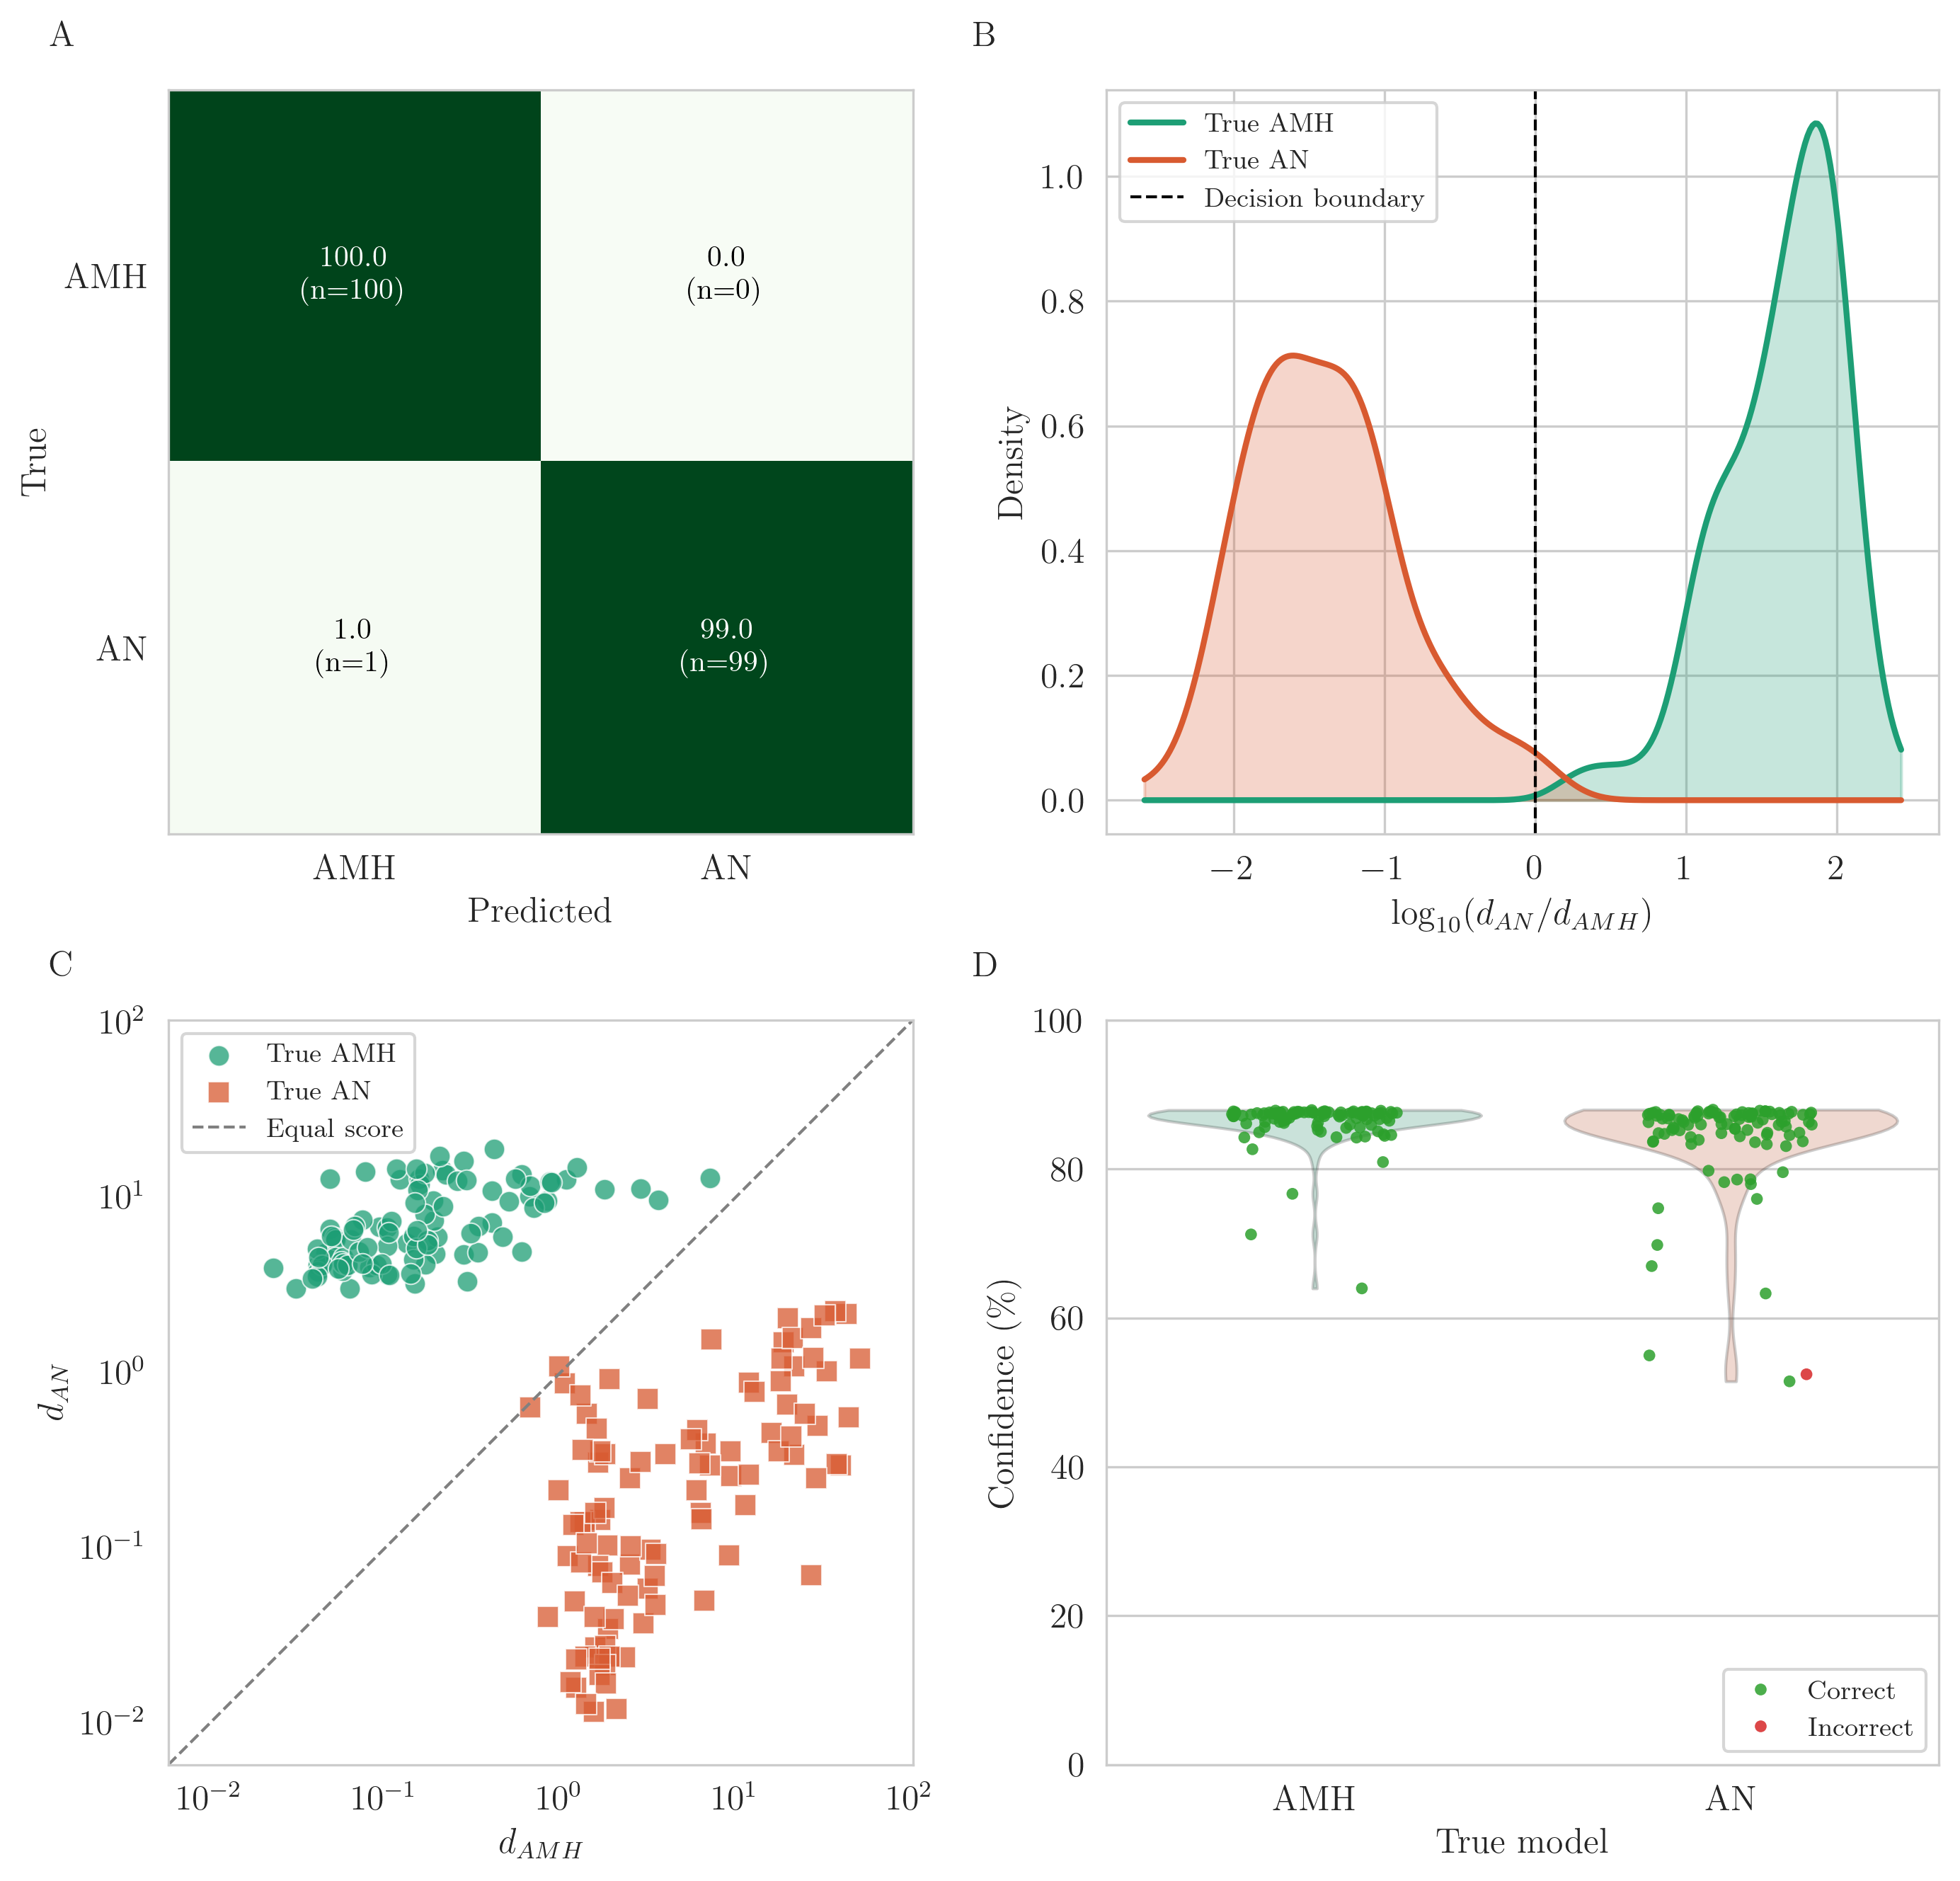

In [ ]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'cmr10', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'font.size': 12,
})

fig, axes = plt.subplots(2, 2, figsize=(9.5, 9.0))

panel_kw = dict(x=-0.16, y=1.05, ha='left', va='bottom', fontsize=12,
                 fontweight='bold', family='serif')

#  (A) Normalized confusion matrix
ax = axes[0, 0]
ax.grid(False)
cm = confusion_matrix(results['true_model'], results['model_winner'], labels=['AMH', 'AN'])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(cm_norm, cmap='Greens', vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm_norm[i, j]*100:.1f}%\n(n={cm[i, j]})',
                ha='center', va='center',
                color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=10)
ax.set_xticks([0, 1]); ax.set_xticklabels(['AMH', 'AN'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['AMH', 'AN'])
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.text(transform=ax.transAxes, s='A', **panel_kw)

# (B) Decision-statistic separation (KDE)
ax = axes[0, 1]
for label, color in [('AMH', AMH_COLOR), ('AN', AN_COLOR)]:
    vals = results.loc[results['true_model'] == label, 'log_ratio'].replace(
        [np.inf, -np.inf], np.nan).dropna()
    kde = gaussian_kde(vals)
    xs = np.linspace(results['log_ratio'].min(), results['log_ratio'].max(), 300)
    ax.plot(xs, kde(xs), color=color, lw=2, label=f'True {label}')
    ax.fill_between(xs, kde(xs), color=color, alpha=0.25)
ax.axvline(0, color='k', linestyle='--', lw=1, label='Decision boundary')
ax.set_xlabel(r'$\log_{10}(d_{AN}/d_{AMH})$')
ax.set_ylabel('Density')
ax.legend(fontsize=9)
ax.text(transform=ax.transAxes, s='B', **panel_kw)

#  (C) Discrepancy score scatter (log-log)
ax = axes[1, 0]
ax.grid(False)
for label, color, marker in [('AMH', AMH_COLOR, 'o'), ('AN', AN_COLOR, 's')]:
    sub = results[results['true_model'] == label]
    ax.scatter(sub['d_AMH'], sub['d_AN'], label=f'True {label}',
               color=color, marker=marker, alpha=0.75,
               edgecolors='white', linewidth=0.5, s=50)
lo = float(results[['d_AMH', 'd_AN']].to_numpy().min()) * 0.5
hi = float(results[['d_AMH', 'd_AN']].to_numpy().max()) * 2.0
ax.plot([lo, hi], [lo, hi], '--', color='gray', lw=1, label='Equal score')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel(r'$d_{AMH}$'); ax.set_ylabel(r'$d_{AN}$')
ax.legend(fontsize=9)
ax.set_aspect('equal')
ax.text(transform=ax.transAxes, s='C', **panel_kw)

# (D) Confidence distribution (violin, split by outcome)
ax = axes[1, 1]
order = ['AMH', 'AN']
conf_pct = results['model_conf'] * 100
sns.violinplot(
    data=results, x='true_model', y=conf_pct, order=order,
    palette=[AMH_COLOR, AN_COLOR], inner=None, cut=0, linewidth=1,
    alpha=0.25, ax=ax,
)
sns.stripplot(
    data=results, x='true_model', y=conf_pct, order=order,
    hue='correct', hue_order=[True, False],
    palette={True: '#2ca02c', False: '#d62728'},
    dodge=False, alpha=0.85, size=4, jitter=0.2, ax=ax,
)
ax.set_xlabel('True model')
ax.set_ylabel('Confidence ($\%$)')
ax.set_ylim(0, 100)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Correct', 'Incorrect'], title=None, loc='lower right', fontsize=9)
ax.text(transform=ax.transAxes, s='D', **panel_kw)

plt.tight_layout()
plt.subplots_adjust(wspace=0.18, hspace=0.25)
plt.savefig('model_selecction_results/combined_2x2_panel.png', dpi=300, bbox_inches='tight')
#plt.savefig('model_selecction_results/combined_2x2_panel.pdf', bbox_inches='tight')
plt.show()